In [1]:
# Instala os pacotes necessários caso não estejam disponíveis no ambiente Colab
pacotes <- c("readxl", "dplyr", "tidyr", "ggplot2", "patchwork", "scales", "sidrar", "zoo", "knitr")
novos_pacotes <- pacotes[!(pacotes %in% installed.packages()[,"Package"])]
if(length(novos_pacotes)) install.packages(novos_pacotes, repos = "https://cloud.r-project.org")

library(readxl)
library(dplyr)
library(tidyr)
library(ggplot2)
library(patchwork)
library(scales)
library(sidrar)
library(zoo)
library(knitr)



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
• `` -> `...4`
• `` -> `...5`
• `` -> `...6`
• `` -> `...7`
• `` -> `...8`
• `` -> `...9`
• `` -> `...10`
• `` -> `...11`
• `` -> `...12`
• `` -> `...13`
• `` -> `...14`
• `` -> `...15`
• `` -> `...16`
• `` -> `...17`
• `` -> `...18`
• `` -> `...19`
New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
• `` -> `...4`
• `` -> `...5`
• `` -> `...6`
• `` -> `...7`


Variação Percentual (1º Trimestre 2026 vs 2º Trimestre 2026):

Força de Trabalho Total:  +0.18%
Homens:                   +0.18%
Mulheres:                 +0.18%
Faixa Etária Referência:  +0.18%


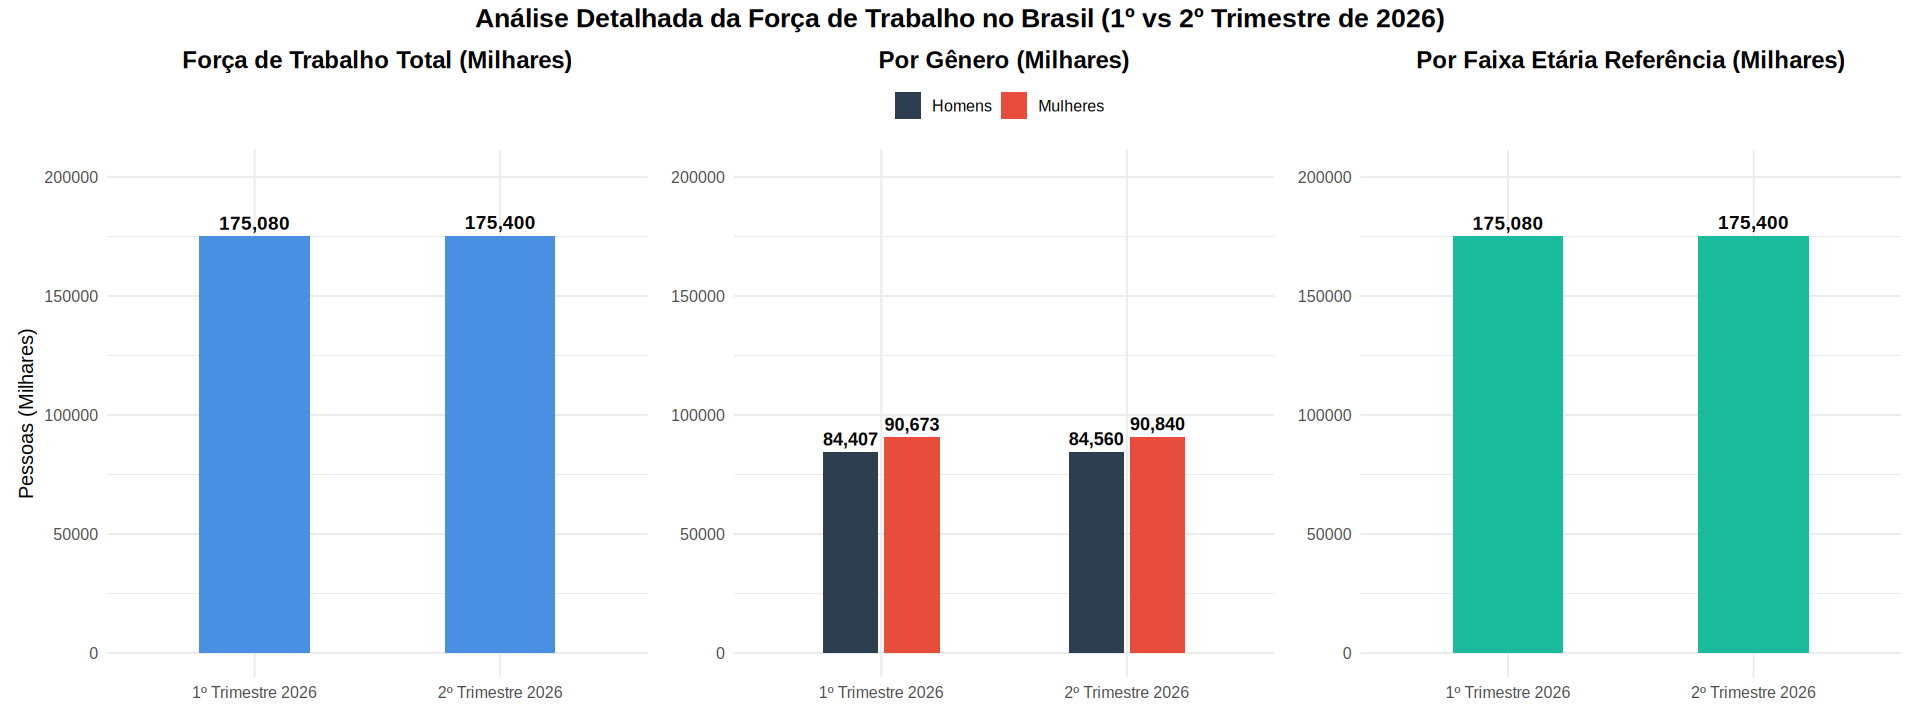

In [2]:
extrair_taxa_excel <- function(caminho_arquivo, termo_busca, num_colunas) {
  df_excel <- read_excel(caminho_arquivo, col_names = FALSE)

  # Localiza a linha inicial pelo termo de busca
  linha_inicio <- which(apply(df_excel, 1, function(r) grepl(termo_busca, paste(r, collapse = " "))))[1]
  if (is.na(linha_inicio)) linha_inicio <- 1

  # Busca dinamicamente a linha contendo "Brasil" abaixo da linha de início
  sub_df <- df_excel[linha_inicio:nrow(df_excel), ]
  rel_brasil <- which(apply(sub_df, 1, function(r) any(grepl("Brasil", as.character(r)))))[1]

  linha_brasil <- if (!is.na(rel_brasil)) linha_inicio + rel_brasil - 1 else linha_inicio + 4

  dados_brasil <- as.character(df_excel[linha_brasil, 2:(num_colunas + 1)])
  valores <- suppressWarnings(as.numeric(dados_brasil))
  valores[is.na(valores)] <- 0.0

  return(valores)
}

# 1. Carregamento e extração (Índices em R começam em 1, diferente do 0 no Python)
arq_sexo <- "/content/Tabela 4093 SIDRA IBGE.xlsx"
arq_idade <- "/content/Tabela 4094 SIDRA IBGE.xlsx"

dados_sexo <- extrair_taxa_excel(arq_sexo, "Pessoas de 14 anos ou mais de idade", 18)
taxa_total_1t26  <- dados_sexo[13]
taxa_total_2t26  <- dados_sexo[16]
taxa_homem_1t26  <- dados_sexo[14]
taxa_homem_2t26  <- dados_sexo[17]
taxa_mulher_1t26 <- dados_sexo[15]
taxa_mulher_2t26 <- dados_sexo[18]

dados_idade <- extrair_taxa_excel(arq_idade, "Pessoas de 14 anos ou mais de idade", 6)
taxa_idade_1t26 <- dados_idade[5]
taxa_idade_2t26 <- dados_idade[6]

# Cálculo das variações percentuais (1T26 vs 2T26)
var_total  <- ((taxa_total_2t26 - taxa_total_1t26) / taxa_total_1t26) * 100
var_homem  <- ((taxa_homem_2t26 - taxa_homem_1t26) / taxa_homem_1t26) * 100
var_mulher <- ((taxa_mulher_2t26 - taxa_mulher_1t26) / taxa_mulher_1t26) * 100
var_idade  <- ((taxa_idade_2t26 - taxa_idade_1t26) / taxa_idade_1t26) * 100

cat("Variação Percentual (1º Trimestre 2026 vs 2º Trimestre 2026):\n\n")
cat(sprintf("Força de Trabalho Total:  %+.2f%%\n", var_total))
cat(sprintf("Homens:                   %+.2f%%\n", var_homem))
cat(sprintf("Mulheres:                 %+.2f%%\n", var_mulher))
cat(sprintf("Faixa Etária Referência:  %+.2f%%\n", var_idade))

# 2. Construção dos 3 Gráficos em Painel (usando ggplot2 + patchwork)
limite_y <- max(taxa_mulher_1t26, taxa_total_1t26, taxa_idade_1t26, 100.0) * 1.15
trimestres <- c("1º Trimestre 2026", "2º Trimestre 2026")

df_g1 <- data.frame(Trimestre = trimestres, Valor = c(taxa_total_1t26, taxa_total_2t26))
p1 <- ggplot(df_g1, aes(x = Trimestre, y = Valor)) +
  geom_col(fill = "#4a90e2", width = 0.45) +
  geom_text(aes(label = comma(Valor)), vjust = -0.5, fontface = "bold", size = 4) +
  ylim(0, limite_y) +
  labs(title = "Força de Trabalho Total (Milhares)", y = "Pessoas (Milhares)", x = NULL) +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold", hjust = 0.5))

df_g2 <- data.frame(
  Trimestre = rep(trimestres, each = 2),
  Genero = rep(c("Homens", "Mulheres"), times = 2),
  Valor = c(taxa_homem_1t26, taxa_mulher_1t26, taxa_homem_2t26, taxa_mulher_2t26)
)
p2 <- ggplot(df_g2, aes(x = Trimestre, y = Valor, fill = Genero)) +
  geom_col(position = position_dodge(width = 0.5), width = 0.45) +
  geom_text(aes(label = comma(Valor)), position = position_dodge(width = 0.5), vjust = -0.5, fontface = "bold", size = 3.8) +
  scale_fill_manual(values = c("Homens" = "#2c3e50", "Mulheres" = "#e74c3c")) +
  ylim(0, limite_y) +
  labs(title = "Por Gênero (Milhares)", y = NULL, x = NULL, fill = NULL) +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold", hjust = 0.5), legend.position = "top")

df_g3 <- data.frame(Trimestre = trimestres, Valor = c(taxa_idade_1t26, taxa_idade_2t26))
p3 <- ggplot(df_g3, aes(x = Trimestre, y = Valor)) +
  geom_col(fill = "#1abc9c", width = 0.45) +
  geom_text(aes(label = comma(Valor)), vjust = -0.5, fontface = "bold", size = 4) +
  ylim(0, limite_y) +
  labs(title = "Por Faixa Etária Referência (Milhares)", y = NULL, x = NULL) +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold", hjust = 0.5))

options(repr.plot.width = 16, repr.plot.height = 6)
(p1 | p2 | p3) +
  plot_annotation(
    title = "Análise Detalhada da Força de Trabalho no Brasil (1º vs 2º Trimestre de 2026)",
    theme = theme(plot.title = element_text(size = 16, face = "bold", hjust = 0.5))
  )


In [7]:
# 1. Une e recria o painel de gráficos completos utilizando o patchwork
painel_completo <- (p1 | p2 | p3) +
  plot_annotation(
    title = "Análise Detalhada da Força de Trabalho no Brasil (1º vs 2º Trimestre de 2026)",
    theme = theme(plot.title = element_text(size = 16, face = "bold", hjust = 0.5))
  )

# 2. Exporta o painel de gráficos nos formatos PNG e PDF
ggsave("/content/painel_forca_trabalho.png", plot = painel_completo, width = 16, height = 6, dpi = 300)
ggsave("/content/painel_forca_trabalho.pdf", plot = painel_completo, width = 16, height = 6)

cat("Imagens exportadas com sucesso:\n")
cat("- /content/painel_forca_trabalho.png\n")
cat("- /content/painel_forca_trabalho.pdf\n")

Imagens exportadas com sucesso:
- /content/painel_forca_trabalho.png
- /content/painel_forca_trabalho.pdf


In [3]:
df_tabela_4093 <- read_excel("/content/Tabela 4093 SIDRA IBGE.xlsx", n_max = 10)
df_tabela_4093[is.na(df_tabela_4093)] <- ""

# Limpa nomes de colunas "Unnamed" / "...2", "...3" gerados pelo readxl
names(df_tabela_4093) <- ifelse(grepl("^\\.\\.\\.", names(df_tabela_4093)), "", names(df_tabela_4093))

kable(df_tabela_4093, format = "pipe", align = "c")


New names:
• `` -> `...2`
• `` -> `...3`
• `` -> `...4`
• `` -> `...5`
• `` -> `...6`
• `` -> `...7`
• `` -> `...8`
• `` -> `...9`
• `` -> `...10`
• `` -> `...11`
• `` -> `...12`
• `` -> `...13`
• `` -> `...14`
• `` -> `...15`
• `` -> `...16`
• `` -> `...17`
• `` -> `...18`
• `` -> `...19`




| Tabela 4093 - Pessoas de 14 anos ou mais de idade, total, na força de trabalho, ocupadas, desocupadas, fora da força de trabalho, em situação de informalidade e respectivas taxas e níveis, por sexo |                   |        |          |                   |        |          |                   |        |          |                   |        |          |                   |        |          |                   |        |          |
|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------:|:-----------------:|:------:|:--------:|:-----------------:|:------:|:--------:|:-----------------:|:------:|:--------:|:-----------------:|:------:|:--------:|:-----------------:|:------:|:--------:|:-----------------:|:------:|:--------:|
|                                                                     Variável - Pessoas de 14 anos ou mais de ida

New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
• `` -> `...4`
• `` -> `...5`
• `` -> `...6`
• `` -> `...7`




|     Trimestre     | Pessoas (Milhares) | Variação Trimestral (%) | Variação Interanual (%) |
|:-----------------:|:------------------:|:-----------------------:|:-----------------------:|
| 1º trimestre 2025 |      173,761       |            -            |            -            |
| 2º trimestre 2025 |      174,079       |         +0.18%          |            -            |
| 3º trimestre 2025 |      174,411       |         +0.19%          |            -            |
| 4º trimestre 2025 |      174,747       |         +0.19%          |            -            |
| 1º trimestre 2026 |      175,080       |         +0.19%          |         +0.76%          |
| 2º trimestre 2026 |      175,400       |         +0.18%          |         +0.76%          |


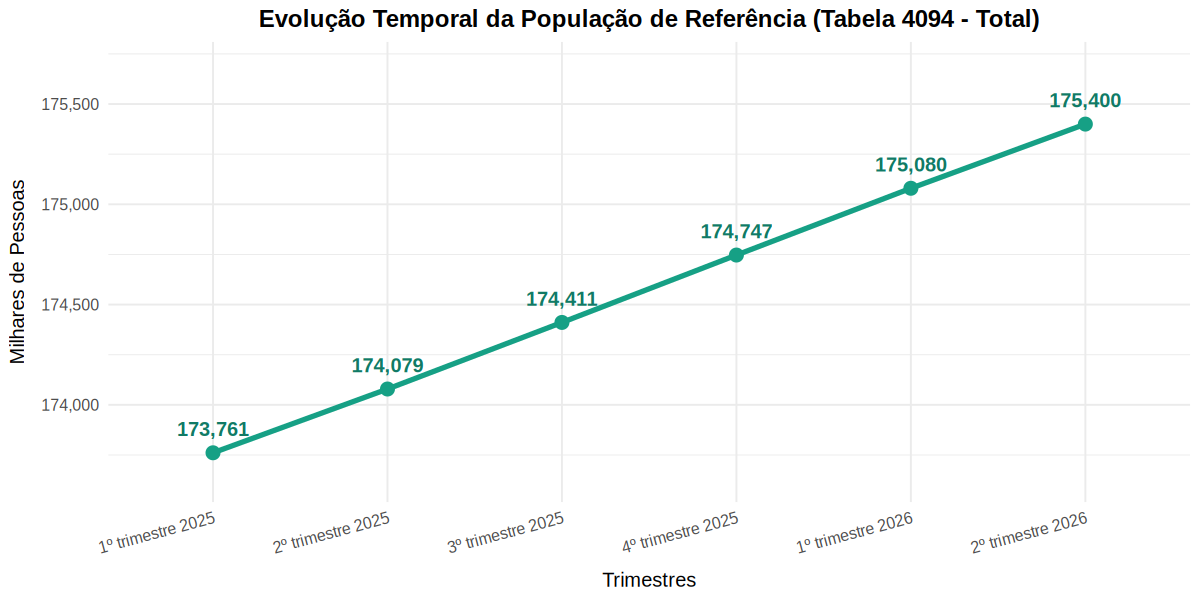

In [4]:
df_raw_4094 <- read_excel("/content/Tabela 4094 SIDRA IBGE.xlsx", col_names = FALSE)

# Linha 4 no R corresponde ao índice 3 no Python; Linha 5 ao índice 4
trimestres_cabecalho <- as.character(df_raw_4094[4, -1])
trimestres_cabecalho <- na.locf(ifelse(trimestres_cabecalho == "NA", NA, trimestres_cabecalho))
grupos_idade_cabecalho <- as.character(df_raw_4094[5, -1])

linha_brasil_idx <- which(df_raw_4094[[1]] == "Brasil")[1]
valores_brasil <- suppressWarnings(as.numeric(as.character(df_raw_4094[linha_brasil_idx, -1])))
valores_brasil[is.na(valores_brasil)] <- 0.0

df_analise_4094 <- data.frame(
  Trimestre = trimestres_cabecalho,
  Grupo_Idade = grupos_idade_cabecalho,
  Pessoas_Milhares = valores_brasil,
  stringsAsFactors = FALSE
)

# Filtra apenas 'Total' e calcula variações QoQ (anterior) e YoY (4 períodos)
df_total_4094 <- df_analise_4094 %>%
  filter(Grupo_Idade == "Total") %>%
  mutate(
    Trimestre = factor(Trimestre, levels = unique(Trimestre)),
    Variacao_Trimestral = ((Pessoas_Milhares / lag(Pessoas_Milhares, 1)) - 1) * 100,
    Variacao_Interanual = ((Pessoas_Milhares / lag(Pessoas_Milhares, 4)) - 1) * 100
  )

# Gráfico de linha da evolução temporal
options(repr.plot.width = 10, repr.plot.height = 5)
ggplot(df_total_4094, aes(x = Trimestre, y = Pessoas_Milhares, group = 1)) +
  geom_line(color = "#16a085", linewidth = 1.5) +
  geom_point(color = "#16a085", size = 3.5) +
  geom_text(aes(label = comma(Pessoas_Milhares)), vjust = -1.2, fontface = "bold", color = "#117a65") +
  scale_y_continuous(expand = expansion(mult = c(0.15, 0.25)), labels = comma) +
  labs(
    title = "Evolução Temporal da População de Referência (Tabela 4094 - Total)",
    x = "Trimestres",
    y = "Milhares de Pessoas"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    axis.text.x = element_text(angle = 15, hjust = 1)
  )

# Tabela consolidada com Variação Trimestral (QoQ) e Interanual (YoY)
tabela_variacoes <- df_total_4094 %>%
  transmute(
    Trimestre,
    `Pessoas (Milhares)` = comma(Pessoas_Milhares),
    `Variação Trimestral (%)` = ifelse(is.na(Variacao_Trimestral), "-", sprintf("%+.2f%%", Variacao_Trimestral)),
    `Variação Interanual (%)` = ifelse(is.na(Variacao_Interanual), "-", sprintf("%+.2f%%", Variacao_Interanual))
  )

print(kable(tabela_variacoes, format = "pipe", align = "c"))


In [5]:
obter_tabela_4093 <- function() {
  tryCatch({
    # Consulta à API SIDRA: Tabela 4093, Nível Territorial 1 (Brasil), todos os períodos
    dados <- get_sidra(
      x = 4093,
      geo = "Brazil",
      period = "all"
    )

    df_long <- dados %>%
      transmute(
        periodo = as.character(`Trimestre (Código)`),
        indicador_categoria = as.character(Variável),
        sexo = as.character(Sexo),
        valor = suppressWarnings(as.numeric(Valor))
      ) %>%
      filter(sexo == "Total") %>%
      select(periodo, indicador_categoria, valor) %>%
      arrange(periodo)

    return(df_long)
  }, error = function(e) {
    message(paste("Erro ao obter dados:", e$message))
    return(data.frame())
  })
}

# Função para acumulado no ano (progressivo e agrupado)
acumulado_no_ano <- function(df, tipo_variavel = "fluxo") {
  df %>%
    mutate(ano = substr(periodo, 1, 4)) %>%
    group_by(ano, indicador_categoria) %>%
    arrange(periodo, .by_group = TRUE) %>%
    mutate(
      acumulado_ano = if (tipo_variavel == "fluxo") {
        cumsum(replace_na(valor, 0))
      } else if (tipo_variavel == "estoque") {
        cummean(valor)
      } else {
        stop("tipo_variavel deve ser 'fluxo' ou 'estoque'")
      }
    ) %>%
    ungroup()
}

# Função para acumulado em janela móvel (12 períodos)
acumulado_12_meses <- function(df, tipo_variavel = "fluxo") {
  df %>%
    group_by(indicador_categoria) %>%
    arrange(periodo, .by_group = TRUE) %>%
    mutate(
      acumulado_12m = if (tipo_variavel == "fluxo") {
        rollapply(valor, width = 12, FUN = sum, na.rm = TRUE, partial = TRUE, align = "right")
      } else if (tipo_variavel == "estoque") {
        rollapply(valor, width = 12, FUN = mean, na.rm = TRUE, partial = TRUE, align = "right")
      } else {
        stop("tipo_variavel deve ser 'fluxo' ou 'estoque'")
      }
    ) %>%
    ungroup()
}

# Execução principal
tabela_long <- obter_tabela_4093()

if (nrow(tabela_long) > 0) {
  write.csv(tabela_long, "tabela_4093_longo.csv", row.names = FALSE, fileEncoding = "UTF-8")
  cat("Arquivo 'tabela_4093_longo.csv' salvo com sucesso.\n\n")

  # Tabela Intermediária 1: Acumulado no ano
  df_acum_ano <- acumulado_no_ano(tabela_long, tipo_variavel = "fluxo")
  tabela_intermediaria_1 <- df_acum_ano %>%
    select(periodo, indicador_categoria, valor = acumulado_ano)

  write.csv(tabela_intermediaria_1, "tabela_intermediaria_1.csv", row.names = FALSE, fileEncoding = "UTF-8")
  cat("TABELA INTERMEDIÁRIA 1 - Acumulado no ano (10 primeiras linhas):\n")
  print(head(tabela_intermediaria_1, 10))

  # Acumulado móvel de 12 períodos
  acum_12m_fluxo <- acumulado_12_meses(tabela_long, tipo_variavel = "fluxo")
  cat("\nAcumulado em 12 períodos (5 primeiras linhas):\n")
  print(head(acum_12m_fluxo, 5))
}


Arquivo 'tabela_4093_longo.csv' salvo com sucesso.

TABELA INTERMEDIÁRIA 1 - Acumulado no ano (10 primeiras linhas):
# A tibble: 10 × 3
   periodo indicador_categoria                                             valor
   <chr>   <chr>                                                           <dbl>
 1 201201  Coeficiente de variação - Distribuição percentual das pessoas …     0
 2 201202  Coeficiente de variação - Distribuição percentual das pessoas …     0
 3 201203  Coeficiente de variação - Distribuição percentual das pessoas …     0
 4 201204  Coeficiente de variação - Distribuição percentual das pessoas …     0
 5 201201  Coeficiente de variação - Distribuição percentual das pessoas …     0
 6 201202  Coeficiente de variação - Distribuição percentual das pessoas …     0
 7 201203  Coeficiente de variação - Distribuição percentual das pessoas …     0
 8 201204  Coeficiente de variação - Distribuição percentual das pessoas …     0
 9 201201  Coeficiente de variação - Distribuição perc